*Setup*

In [ ]:
# Import libraries needed for data analysis and visualization
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Load the e-commerce events dataset
df = pd.read_csv("/content/drive/MyDrive/events.csv")

## ***EDA***

In [ ]:
# Check the dataset size, columns, data types, and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150838 entries, 0 to 150837
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   event_time     150838 non-null  object 
 1   event_type     150838 non-null  object 
 2   product_id     150838 non-null  int64  
 3   category_id    150838 non-null  int64  
 4   category_code  106263 non-null  object 
 5   brand          111478 non-null  object 
 6   price          150838 non-null  float64
 7   user_id        150838 non-null  int64  
 8   user_session   150810 non-null  object 
dtypes: float64(1), int64(3), object(5)
memory usage: 10.4+ MB


In [ ]:
# Check missing values and duplicate rows to assess data quality
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

event_time           0
event_type           0
product_id           0
category_id          0
category_code    44575
brand            39360
price                0
user_id              0
user_session        28
dtype: int64
Duplicates: 111


In [ ]:
# Check event types, price statistics, and the time range of the dataset
print(df["event_type"].value_counts())
print(df["price"].describe())
print(df["event_time"].min(), df["event_time"].max())

event_type
view        136906
cart          8091
purchase      5841
Name: count, dtype: int64
count    150838.000000
mean        112.907193
std         334.405569
min           0.370000
25%          21.810000
50%          51.920000
75%         126.680000
max       64771.060000
Name: price, dtype: float64
2020-09-24 11:57:06 UTC 2020-10-25 14:08:42 UTC


*Cleaning*

In [ ]:
# Remove duplicate records, rows without sessions, and replace missing categories/brands
df_clean = df.drop_duplicates().dropna(subset=["user_session"]).copy()

df_clean["brand"] = df_clean["brand"].fillna("Unknown")
df_clean["category_code"] = df_clean["category_code"].fillna("Unknown")

In [ ]:
# Convert event_time into datetime so we can perform time-based analysis
df_clean["event_time"] = pd.to_datetime(df_clean["event_time"], utc=True)

*Business Analysis*

In [ ]:
# Convert event_time into datetime so we can perform time-based analysis
df_clean["event_time"] = pd.to_datetime(df_clean["event_time"], utc=True)# Create a purchase-only dataset for revenue and purchase analysis
purchase_df = df_clean[df_clean["event_type"] == "purchase"].copy()

total_revenue = purchase_df["price"].sum()
average_purchase_value = purchase_df["price"].mean()
total_purchases = len(purchase_df)

print("Total revenue:", total_revenue)
print("Average purchase value:", average_purchase_value)
print("Total purchases:", total_purchases)

Total revenue: 518868.37
Average purchase value: 88.83211265194316
Total purchases: 5841


*Product Analysis*

In [ ]:
# Calculate purchase count and revenue for each product
product_performance = (
    purchase_df
    .groupby("product_id")
    .agg(
        purchases=("product_id", "size"),
        revenue=("price", "sum")
    )
    .sort_values("revenue", ascending=False)
)

product_performance.head(10)

,purchases,revenue
product_id,,
3791351,125,25536.25
4027952,39,10056.93
4099645,26,7613.58
3760003,20,6451.40
3759997,28,5400.08
4155385,10,5395.70
4079420,12,5394.12
3760001,14,4405.52
4078916,10,4155.40


*Category Analysis*

In [ ]:
# Calculate purchase count and revenue for each product category
category_performance = (
    purchase_df
    .groupby("category_code")
    .agg(
        purchases=("product_id", "size"),
        revenue=("price", "sum")
    )
    .sort_values("revenue", ascending=False)
)

category_performance.head(10)

,purchases,revenue
category_code,,
computers.components.videocards,258,82417.91
computers.peripherals.printer,514,72822.93
Unknown,1315,72511.27
computers.components.cpu,233,42634.45
electronics.telephone,730,25832.59
stationery.cartrige,600,22355.11
electronics.video.projector,29,17470.87
computers.components.motherboard,199,15905.76
computers.peripherals.wifi,120,14427.12


*User Analysis*

In [ ]:
# Calculate basic purchase behavior for each user
user_performance = (
    purchase_df
    .groupby("user_id")
    .agg(
        purchases=("product_id", "size"),
        spending=("price", "sum")
    )
    .sort_values("spending", ascending=False)
)

user_performance.head(10)

,purchases,spending
user_id,,
1515915625519495480,5,5489.08
1515915625520712323,9,4666.99
1515915625526745191,21,4386.75
1515915625524628491,20,3643.88
1515915625526571951,23,3583.39
1515915625461593155,9,3020.80
1515915625415474736,10,2736.50
1515915625521888302,6,2452.10
1515915625521533048,2,2419.96


*Funnel Analysis*

In [ ]:
# Count views, carts, and purchases to measure the customer funnel
funnel = df_clean["event_type"].value_counts()

views = funnel.get("view", 0)
carts = funnel.get("cart", 0)
purchases = funnel.get("purchase", 0)

print("Views:", views)
print("Carts:", carts)
print("Purchases:", purchases)

Views: 136768
Carts: 8090
Purchases: 5841


In [ ]:
# Calculate conversion rates between the major funnel stages
print("View → Cart:", carts / views * 100)
print("Cart → Purchase:", purchases / carts * 100)
print("View → Purchase:", purchases / views * 100)

View → Cart: 5.91512634534394
Cart → Purchase: 72.20024721878863
View → Purchase: 4.270735844642021


*Time Analysis*

In [ ]:
# Create a date column so we can analyze daily activity and revenue
df_clean["date"] = df_clean["event_time"].dt.date

In [ ]:
# Calculate daily revenue from purchase events
daily_revenue = (
    purchase_df
    .groupby(purchase_df["event_time"].dt.date)["price"]
    .sum()
)

*Visualizations*

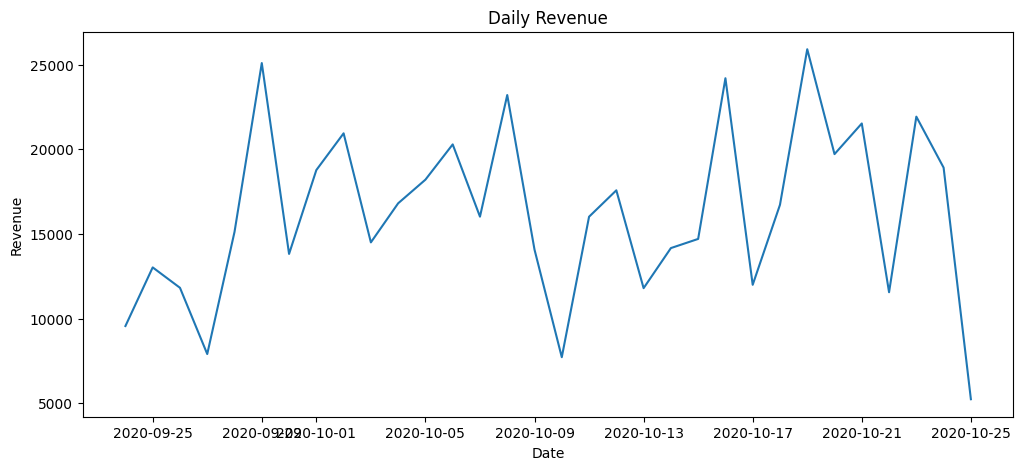

In [ ]:
# Visualize how purchase revenue changes over time
daily_revenue.plot(figsize=(12, 5))
plt.title("Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.show()

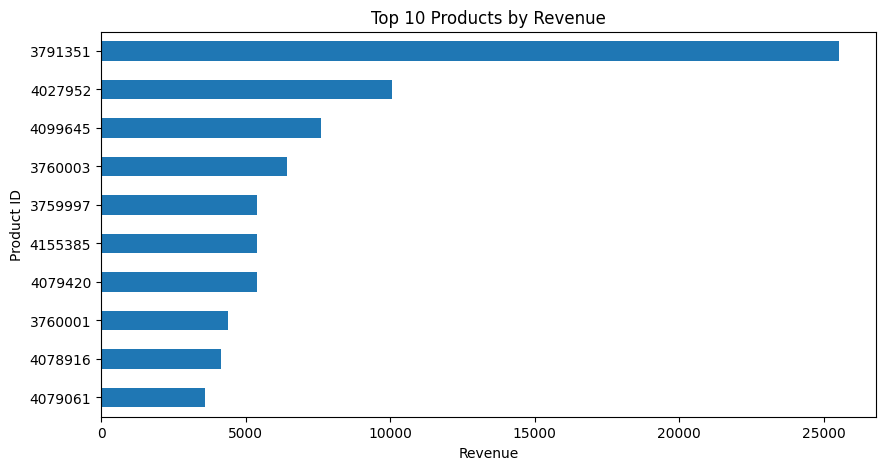

In [ ]:
# Visualize the top products by purchase revenue
product_performance.head(10)["revenue"].sort_values().plot.barh(figsize=(10, 5))

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product ID")
plt.show()

In [ ]:
# Export the cleaned dataset so it can be imported into Power BI
df_clean.to_csv("/content/productiq_clean.csv", index=False)